# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p16"
subproj <- "AVGUSTINOVA_24_25"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

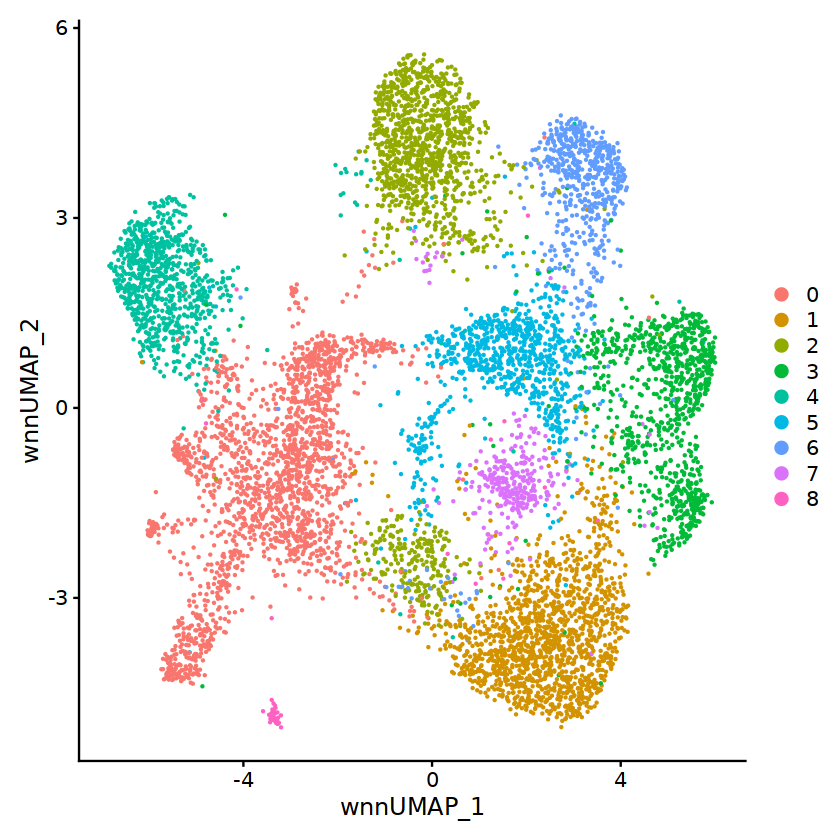

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

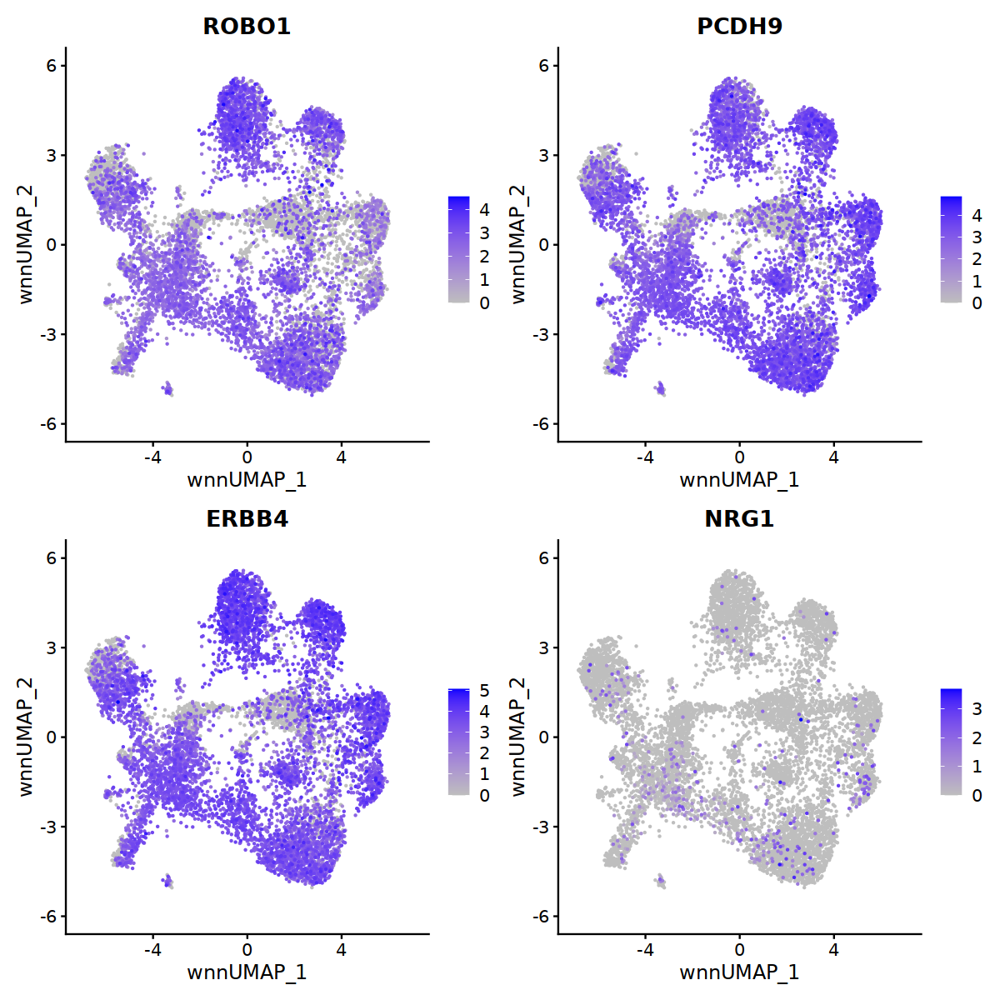

In [11]:
options(repr.plot.width = 10, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("ROBO1","PCDH9", "ERBB4","NRG1"),ncol=2,
            cols = c("gray", "blue"),  order=T)

## Re-normalize

Check whether DecontX has fixed enough the TYR expression in immune cells 

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

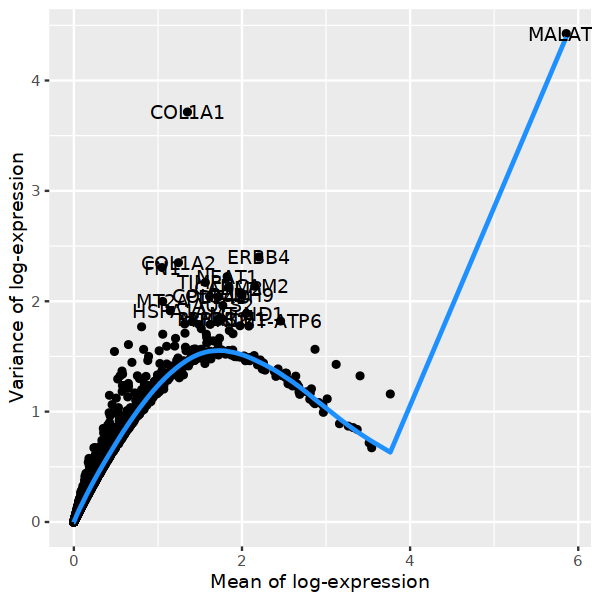

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 4736
[1] 4736


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  FABP4, SLC35F4, MKX, ERBB4, GALNTL6, TFPI2, CADM2, CDH10, TXNDC17, COX6C 
	   FABP5, S100A10, CLDN1, HINT1, ITGA7, SPINT2, TMEM256, LINC00378, GCG, CHCHD5 
	   NCAM2, ATP5MD, TOMM6, ROMO1, COMMD6, PCDH9, CTNNA2, TLE2, CHGB, CSMD1 
Negative:  COL1A1, COL6A1, COL5A1, SPARC, COL6A3, CALD1, GPC6, FN1, LAMB1, THBS2 
	   SERPINE1, SULF1, CACNA1C, COL1A2, KIF26B, AEBP1, IGFBP2, LDB2, BGN, RUNX1 
	   PTPRG, IGFBP7, COL4A2, SLIT2, TCF4, FOXP1, BICC1, VCAN, ADAMTS14, MT2A 
PC_ 2 
Positive:  ERBB4, NCAM2, PRICKLE1, APBB2, AUTS2, CADM2, PDE4D, PCDH9, MIR99AHG, DST 
	   CTNNA2, ROBO1, ROBO2, MRC2, DLC1, CCDC102B, FGFR1, FOXG1, FAM155A, MEG3 
	   CALD1, MAML2, DCBLD2, ADGRL3, TSPAN5, FLRT2, TPD52L1, TRPM3, PPP3CA, GPC6 
Negative:  CD74, MS4A6A, FMN1, C1QB, SAT1, SLCO2B1, C1QA, CD163, C1QC, SLC1A3 
	   IFI30, HLA-DRB1, RASSF4, STAB1, TBXAS1, CELF2, SLC11A1, RBM47, SLC8A1, LRMDA 
	   LAPTM5, AOAH, MERTK, APOC1, RNASE1, CPM, GLUL, FYB1, ITGAX, MSR1 


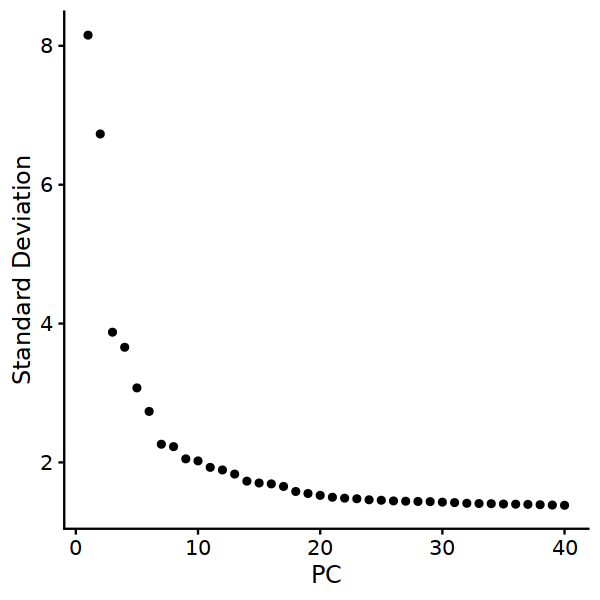

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


18:24:13 UMAP embedding parameters a = 0.9922 b = 1.112

18:24:13 Read 8453 rows and found 20 numeric columns

18:24:13 Using Annoy for neighbor search, n_neighbors = 30

18:24:15 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

18:24:16 Writing NN index file to temp file /scratch_tmp/49729482/RtmpTvX2YK/file2fbb87b81f5d5

18:24:16 Searching Annoy index using 1 thread, search_k = 3000

18:24:19 Annoy recall = 100%

18:24:20 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

18:24:20 19 smooth knn distance failures

18:24:22 Initializing from normalized Laplacian + noise (using irlba)

18:24:23 Commencing optimization for 500 epochs, with 354354 positive edges

18:24:47 Optimization f

In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
    n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

18:25:12 UMAP embedding parameters a = 0.115 b = 1.929

18:25:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

18:25:14 9 smooth knn distance failures

18:25:15 Initializing from normalized Laplacian + noise (using irlba)

18:25:16 Commencing optimization for 500 epochs, with 253190 positive edges

18:25:42 Optimization finished



In [23]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 8453
Number of edges: 337928

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9809
Number of communities: 9
Elapsed time: 0 seconds


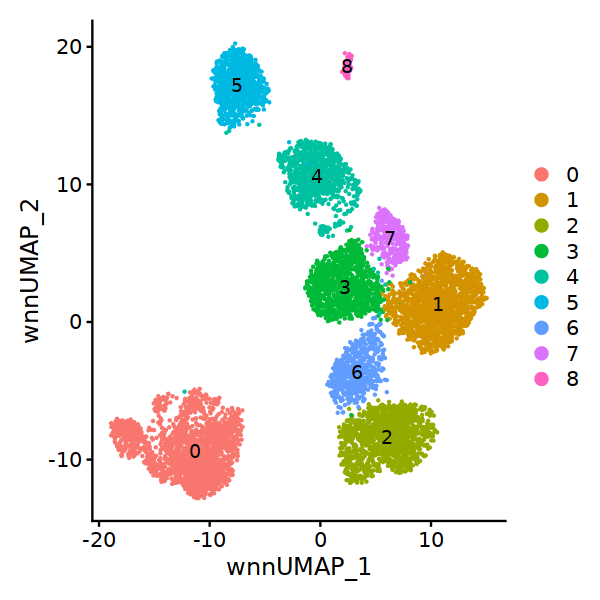

In [24]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

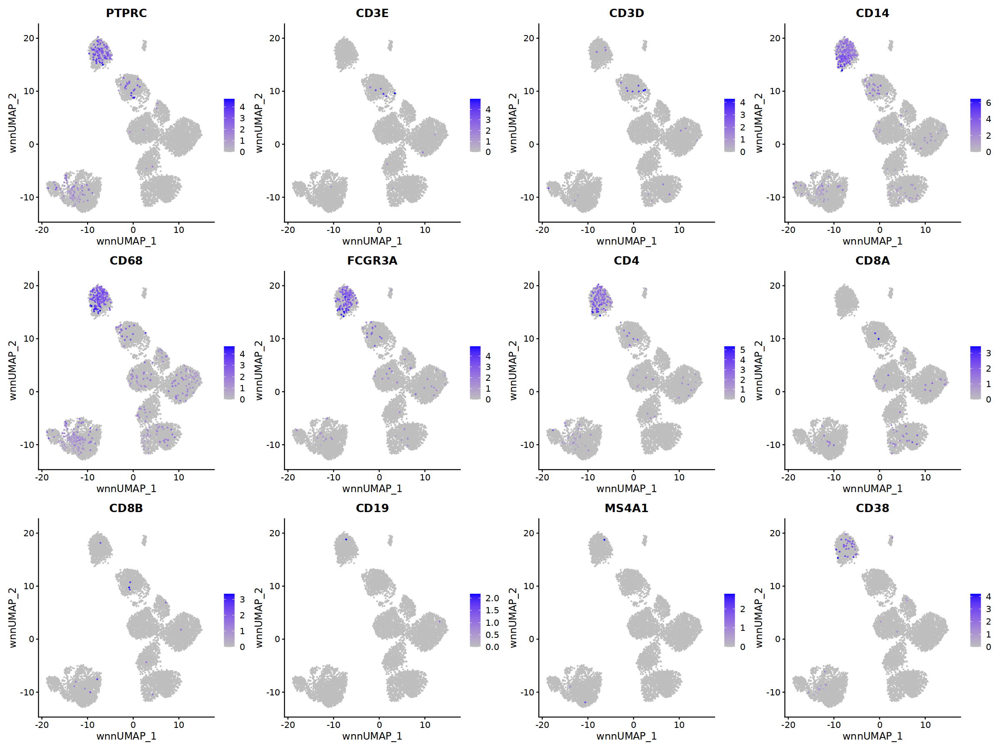

In [25]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

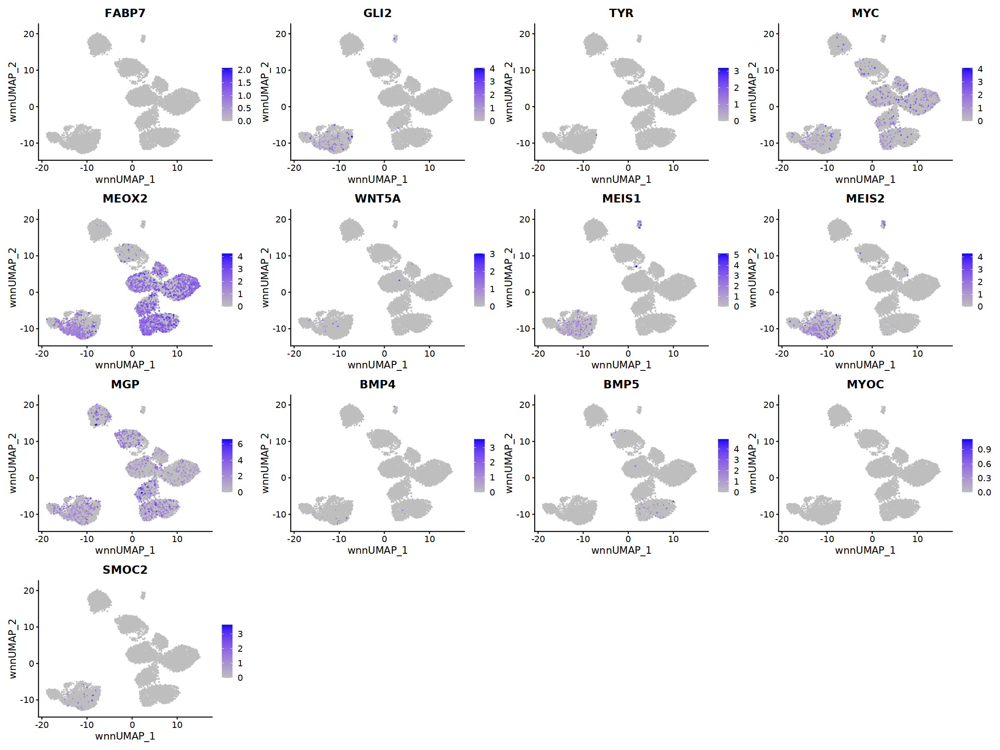

In [26]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

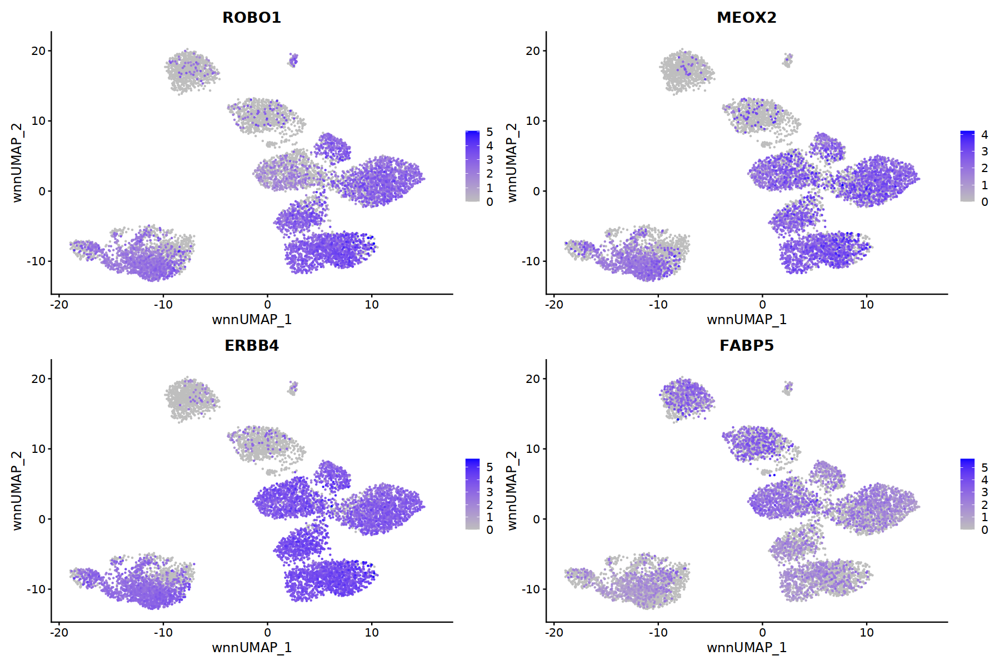

In [27]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("ROBO1","MEOX2", "ERBB4", "FABP5"),ncol=2,
            cols = c("gray", "blue"),  order=T)

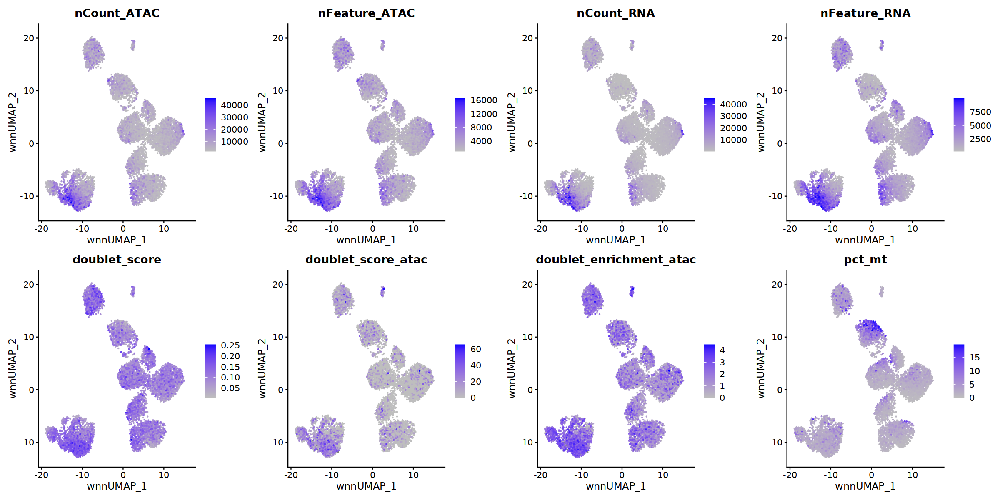

In [28]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

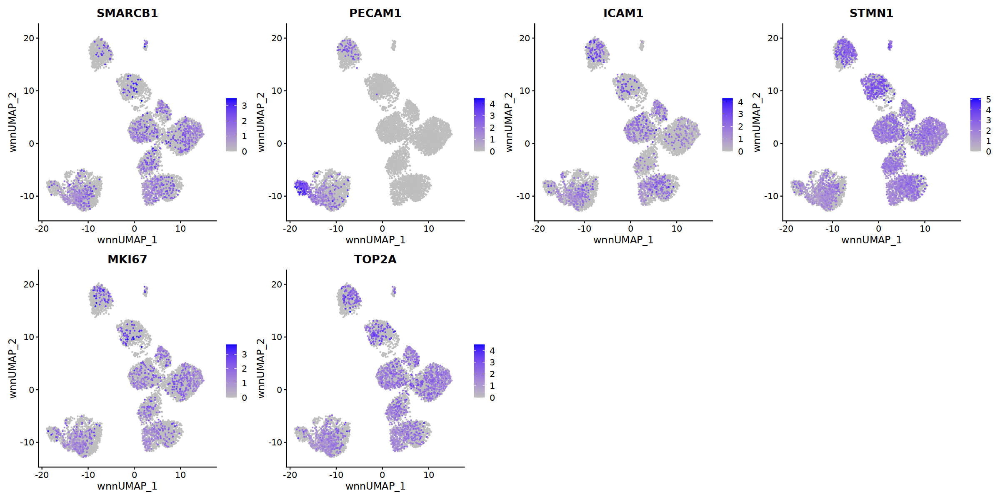

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [30]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



In [31]:
rna.markers %>% 
  dplyr::filter(cluster == "8") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ITGA8,0.000000e+00,4.270286,0.729,0.007,0.000000e+00,8,ITGA8
EYA1,0.000000e+00,3.852562,0.708,0.001,0.000000e+00,8,EYA1
MEIS11,9.142775e-59,3.527682,0.625,0.066,2.741644e-54,8,MEIS1
DACH1,9.005566e-186,3.414095,0.500,0.011,2.700499e-181,8,DACH1
NRG3,1.825552e-224,3.309336,0.521,0.010,5.474281e-220,8,NRG3
DPP6,1.405094e-154,3.216500,0.479,0.013,4.213456e-150,8,DPP6
TRABD2B,6.863098e-250,3.019852,0.417,0.005,2.058037e-245,8,TRABD2B
BMPER,7.658590e-298,2.914037,0.354,0.002,2.296581e-293,8,BMPER
PAX2,0.000000e+00,2.787721,0.375,0.000,0.000000e+00,8,PAX2


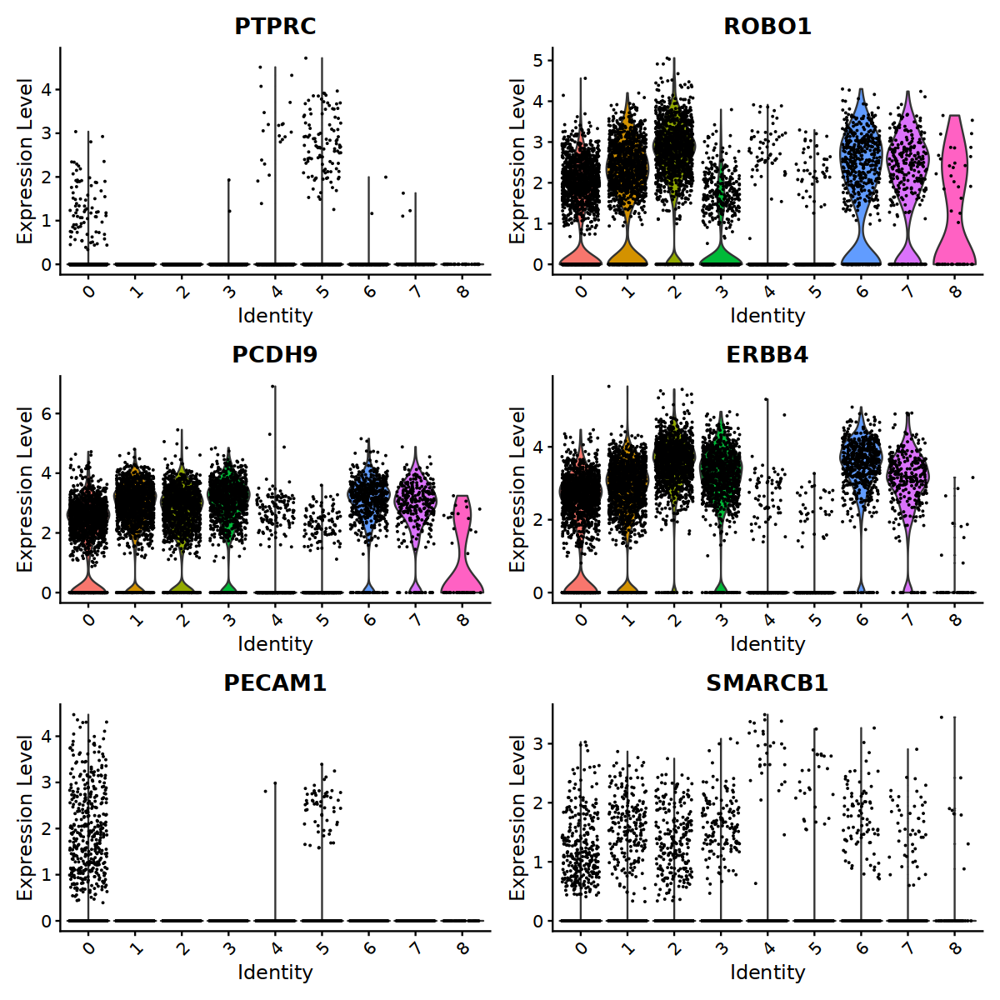

In [32]:
options(repr.plot.width = 10, repr.plot.height = 10)
VlnPlot(seurat_obj, 
            feature=c("PTPRC", "ROBO1","PCDH9", "ERBB4", "PECAM1", "SMARCB1"),ncol=2)

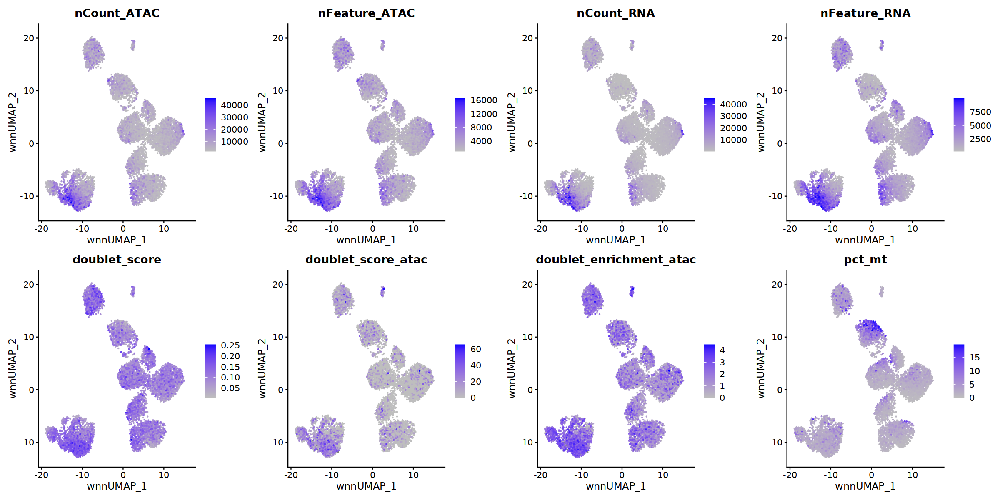

In [33]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

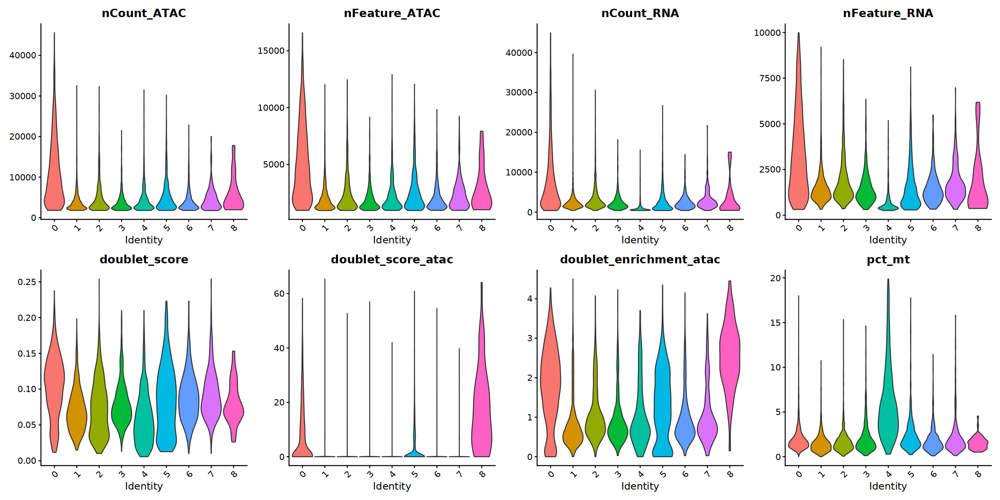

In [34]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

## Filter cells

low quality cells

In [35]:
seurat_obj <- subset(seurat_obj, idents = c("4"), invert = TRUE)

In [36]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [37]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [38]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [39]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

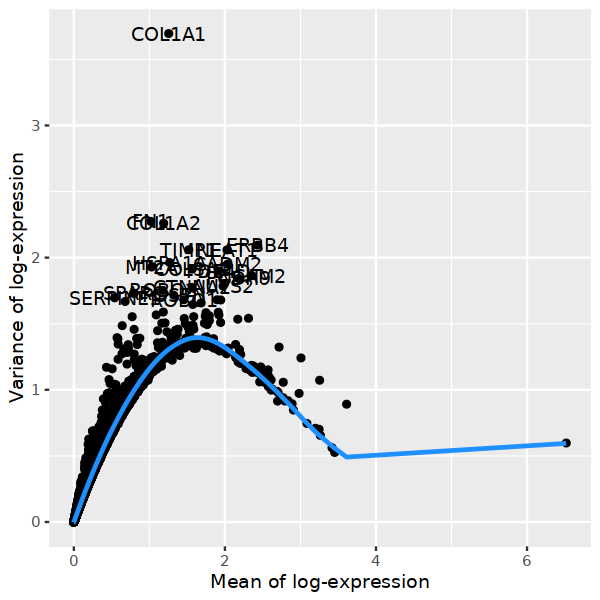

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [41]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 9640
[1] 9640


In [42]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  HGF, ERBB4, CADM2, SLC35F4, FABP4, MKX, GALNTL6, CDH10, NCAM2, PCDH9 
	   TFPI2, MIR99AHG, SPINT2, ADGRL2, CTNNA2, CLDN1, FABP5, ITGA7, S100A10, LINC00378 
	   RNF128, CPNE7, GCG, LINC02432, CNTNAP2, CHGB, CSMD1, TLE2, AGMO, CAPG 
Negative:  COL1A1, COL6A1, SPARC, COL5A1, FN1, COL6A3, COL1A2, CALD1, GPC6, THBS2 
	   AEBP1, LAMB1, IGFBP2, BGN, SULF1, SERPINE1, KIF26B, CACNA1C, IGFBP7, LDB2 
	   PTPRG, COL4A2, MT2A, RUNX1, SLIT2, VCAN, BICC1, TCF4, ADAMTS14, TSHZ2 
PC_ 2 
Positive:  ERBB4, NCAM2, PRICKLE1, CADM2, AUTS2, APBB2, PCDH9, DST, MIR99AHG, PDE4D 
	   TENM3, CTNNA2, ADGRL2, ROBO1, HERC4, ADAMTS6, COL5A2, AGMO, ROBO2, FGFR1 
	   DLC1, CCDC102B, FOXG1, NBEA, MRC2, ADGRL3, TPD52L1, MAML2, FAM155A, FLRT2 
Negative:  CD74, MS4A6A, C1QB, SAT1, FMN1, C1QA, SLCO2B1, C1QC, CD163, SLC1A3 
	   IFI30, HLA-DRB1, STAB1, RBM47, RASSF4, CELF2, SLC11A1, TBXAS1, LRMDA, LAPTM5 
	   SLC8A1, APOC1, AOAH, GLUL, RNASE1, CPM, SRGN, TYROBP, MERTK, HLA-

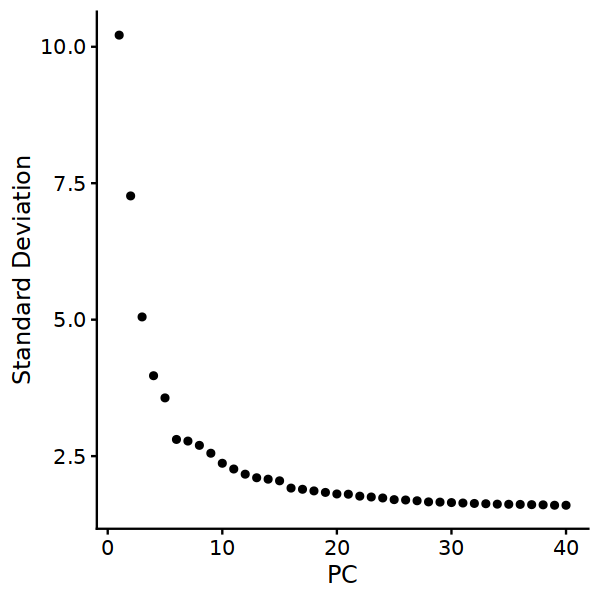

In [43]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [44]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [45]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



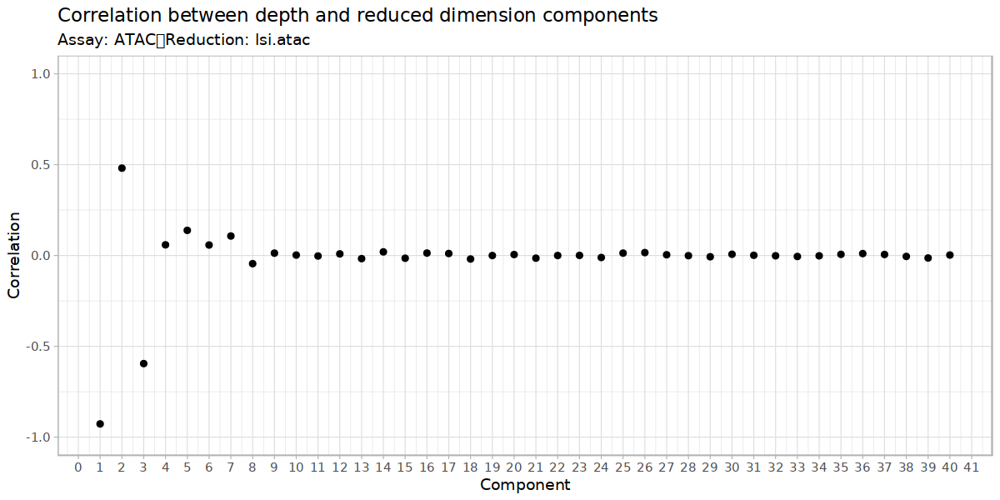

In [46]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

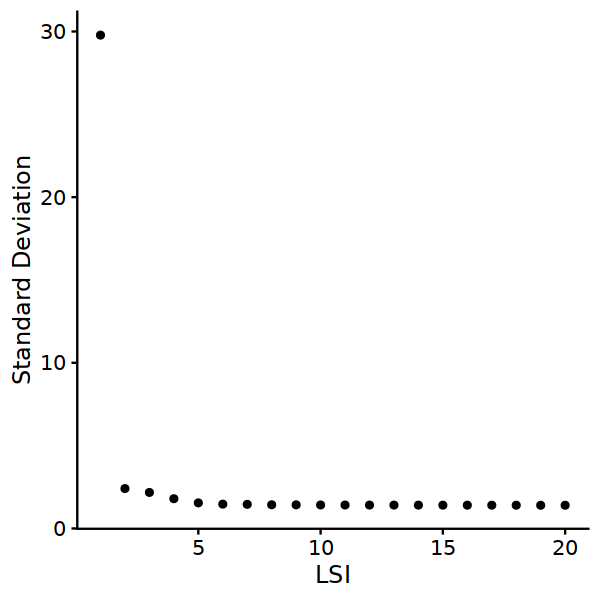

In [47]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [48]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [49]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells
)

18:32:18 UMAP embedding parameters a = 0.115 b = 1.929

18:32:19 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

18:32:20 Found 2 connected components, 
falling back to random initialization

18:32:21 Initializing from uniform random

18:32:21 Commencing optimization for 500 epochs, with 223858 positive edges

18:32:44 Optimization finished



In [50]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7561
Number of edges: 299654

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9802
Number of communities: 8
Elapsed time: 0 seconds


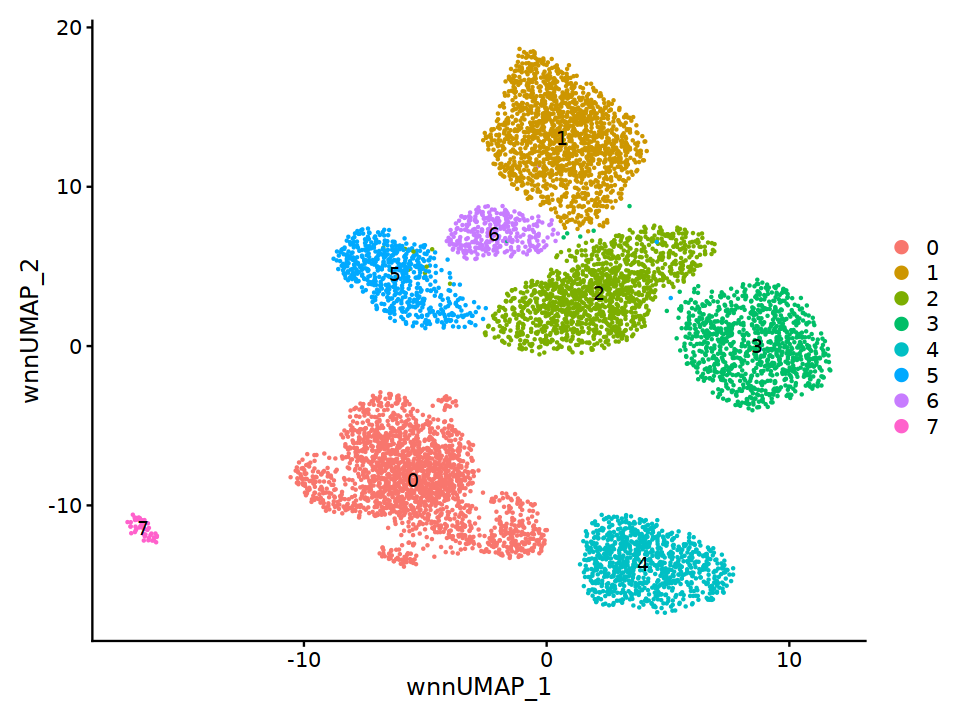

In [51]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [52]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



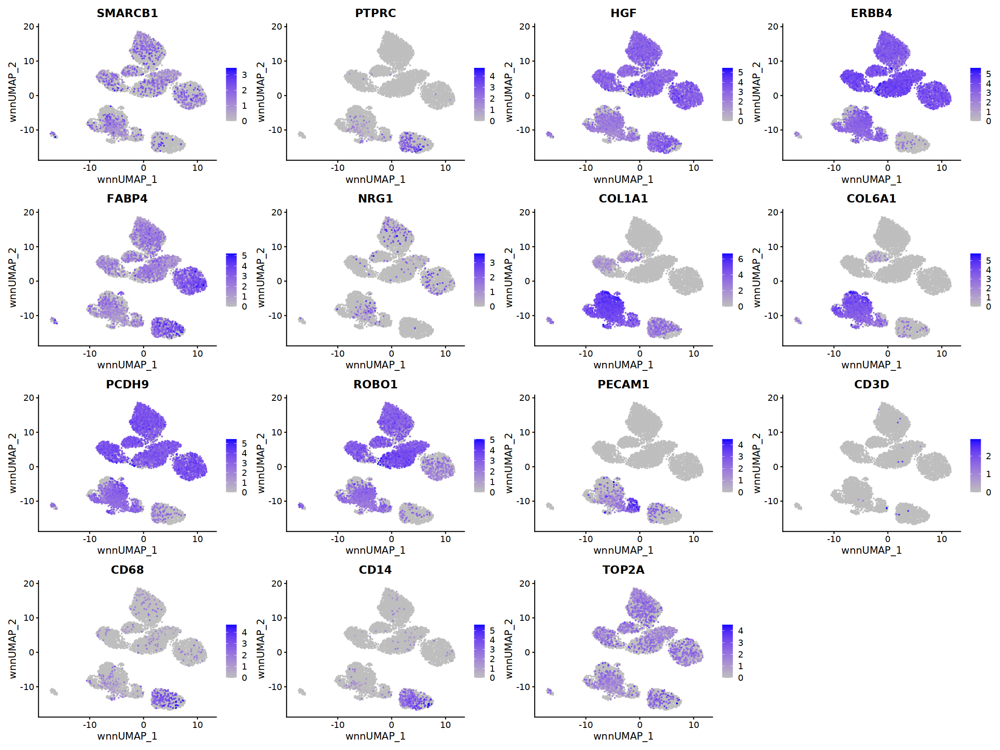

In [53]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC","HGF","ERBB4", "FABP4","NRG1",
                              "COL1A1","COL6A1", "PCDH9","ROBO1", 
                              "PECAM1","CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),order=T)

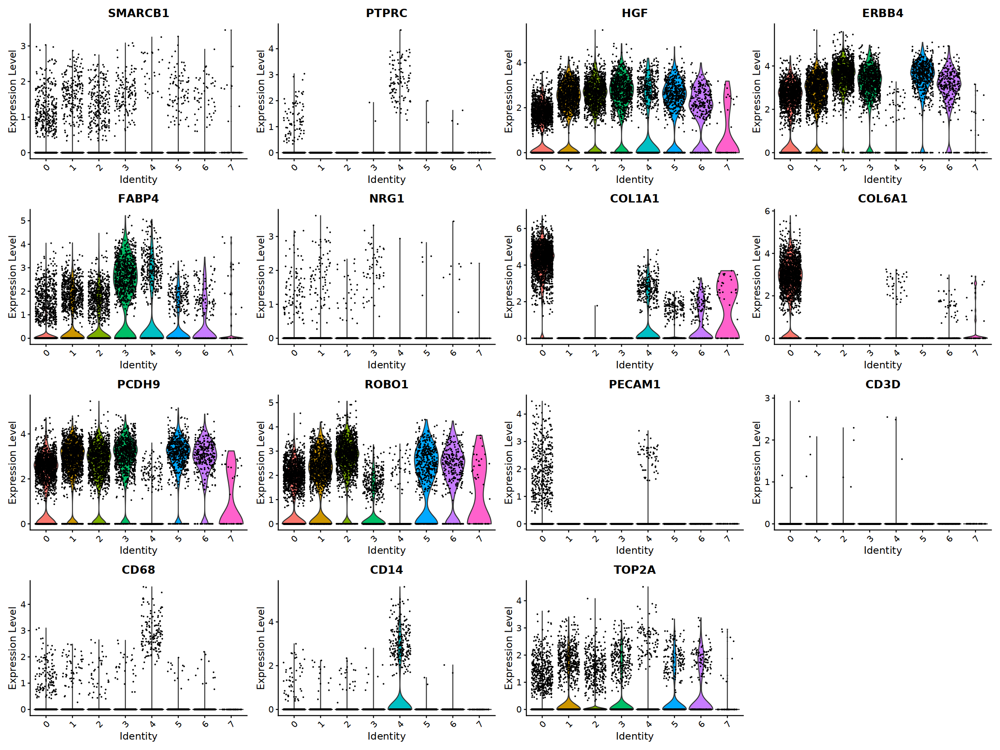

In [54]:
VlnPlot(seurat_obj, feature=vars2plot)

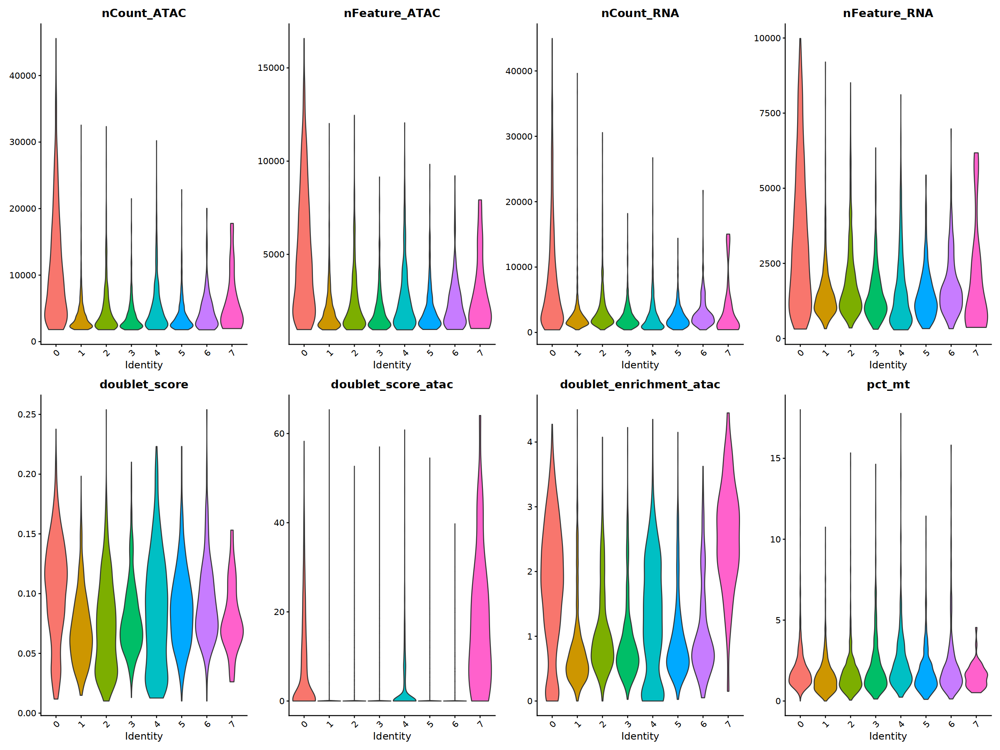

In [55]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4, pt.size = 0)

In [56]:
rna.markers %>% 
  dplyr::filter(cluster == "7") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ITGA8,0.000000e+00,4.269116,0.729,0.007,0.000000e+00,7,ITGA8
EYA1,0.000000e+00,3.851404,0.708,0.001,0.000000e+00,7,EYA1
MEIS11,1.226251e-52,3.505212,0.625,0.074,3.663056e-48,7,MEIS1
DACH1,4.987553e-169,3.413331,0.500,0.012,1.489882e-164,7,DACH1
NRG3,1.208547e-200,3.300010,0.521,0.011,3.610173e-196,7,NRG3
DPP6,3.252547e-139,3.210801,0.479,0.014,9.716007e-135,7,DPP6
TRABD2B,2.107718e-223,3.017373,0.417,0.005,6.296175e-219,7,TRABD2B
BMPER,2.683948e-266,2.912676,0.354,0.003,8.017488e-262,7,BMPER
PAX2,0.000000e+00,2.789852,0.375,0.000,0.000000e+00,7,PAX2


### Rename

In [57]:
rename_clusters <- c("0"="Fibroblast", 
                     "1"="Tumor TRPM3",
                     "2"="Tumor ADGRL3", 
                     "3"="Tumor FABP4",
                     "4"="Monocytes-Macrophages",
                     "5"="Tumor FRMD5",
                     "6"="Tumor TMEFF2",
                     "7"="NPC")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [58]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep]

In [59]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [60]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [61]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [62]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune

Calculating cluster Other stromal



In [63]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

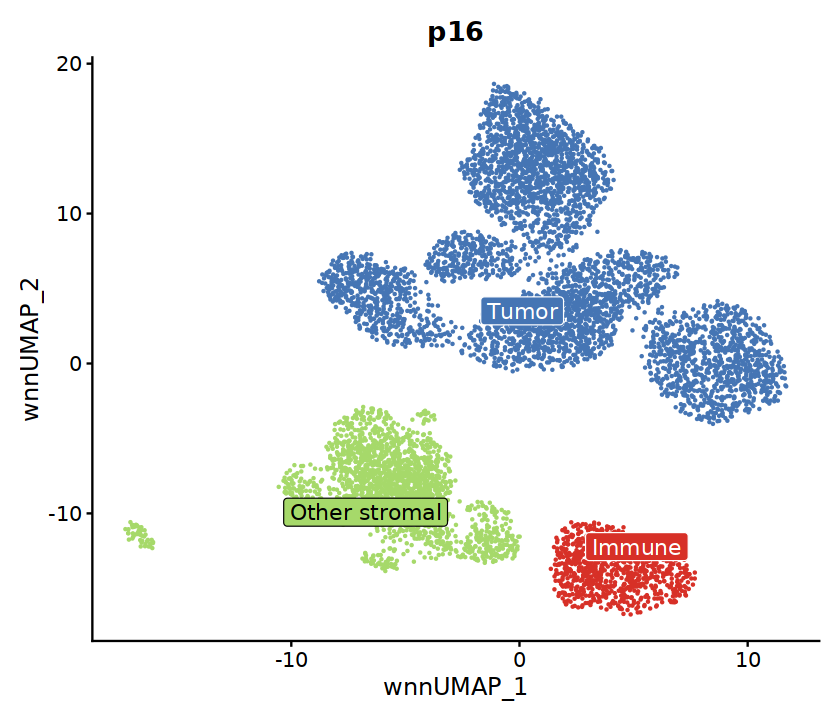

In [64]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [90]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [66]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [67]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

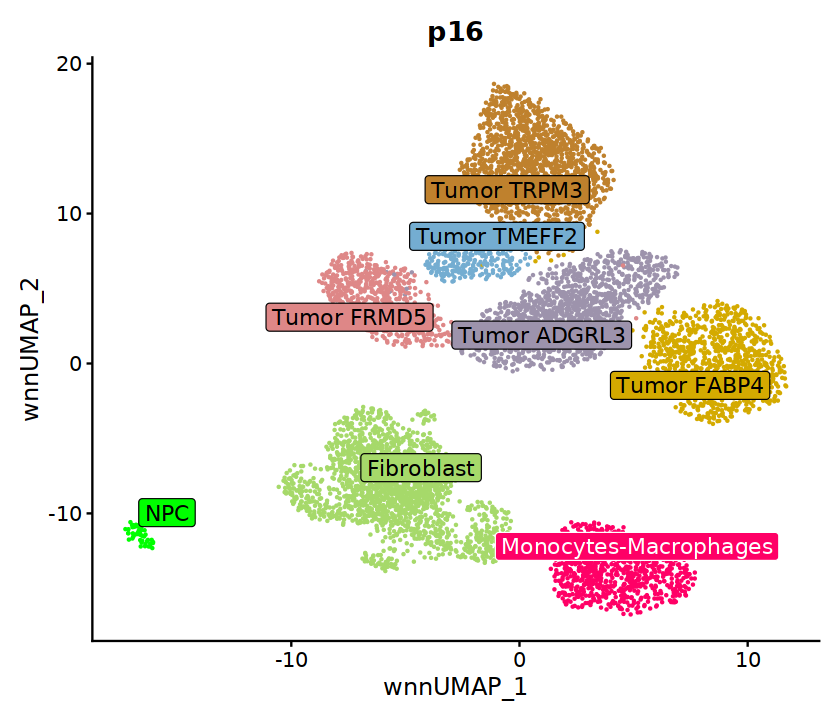

In [68]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [69]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

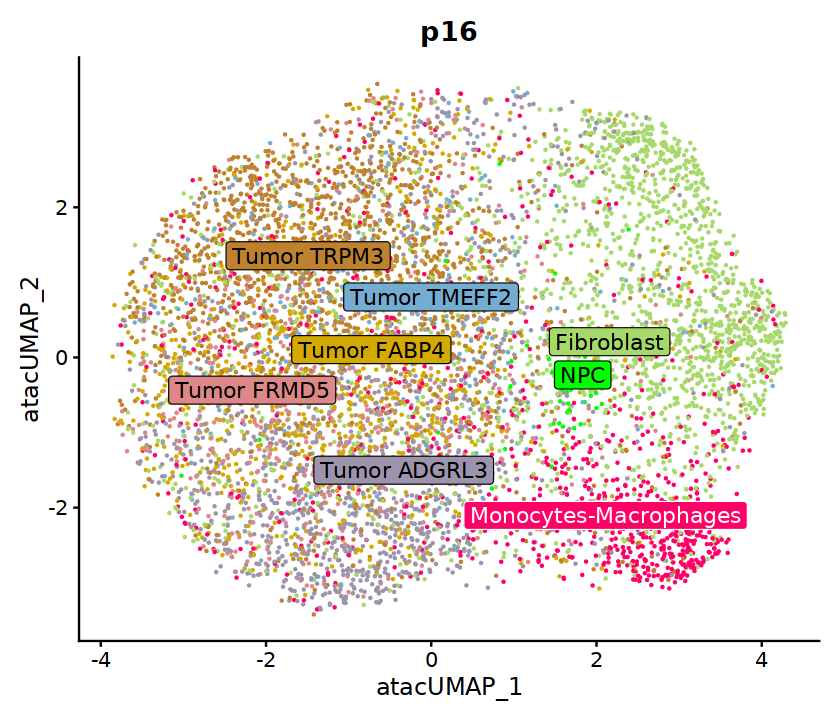

In [70]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [71]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

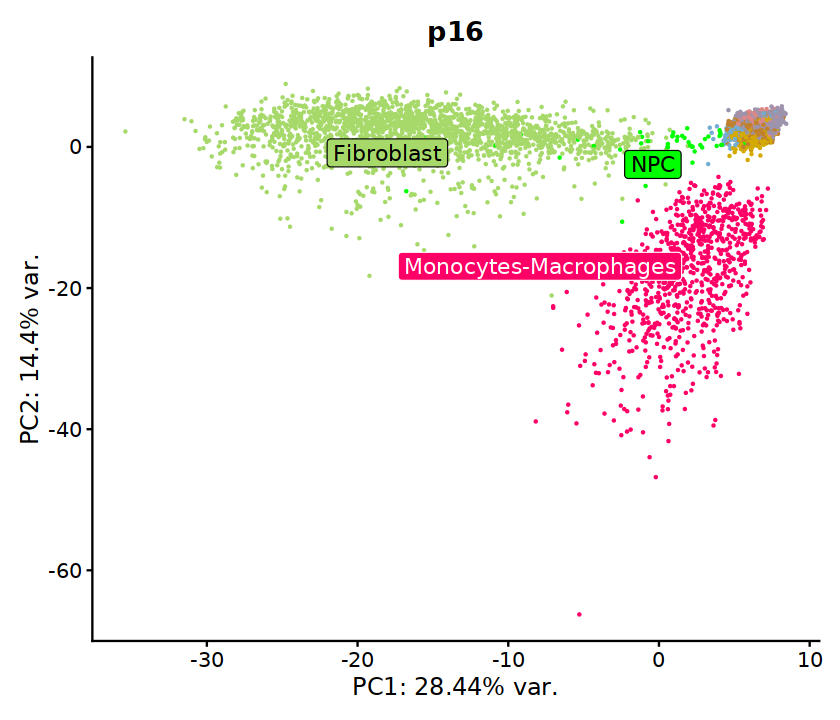

In [72]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

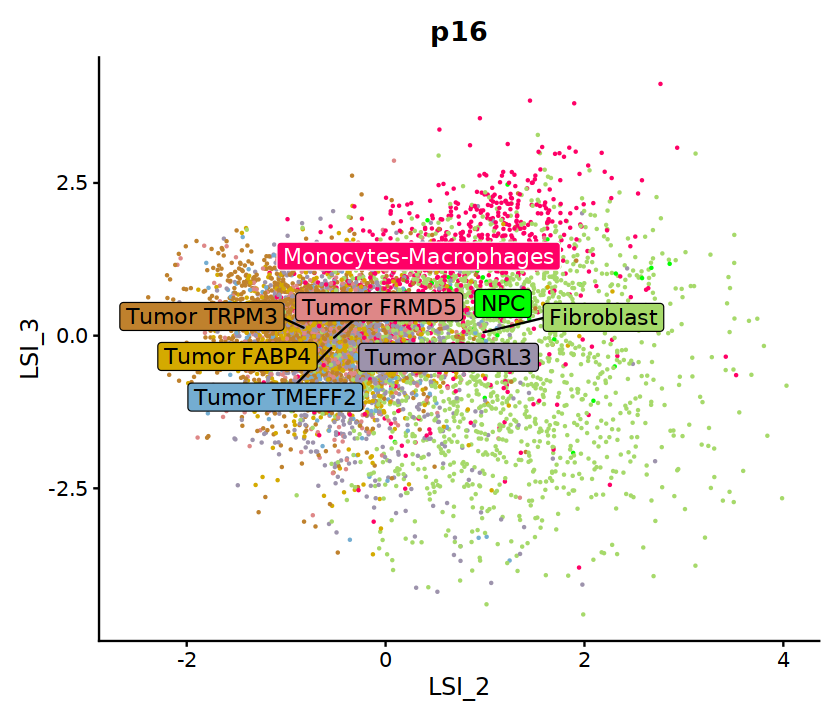

In [73]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

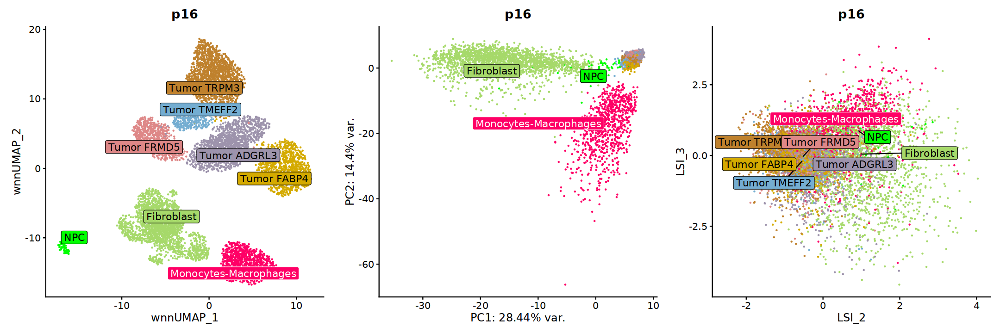

In [74]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [75]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

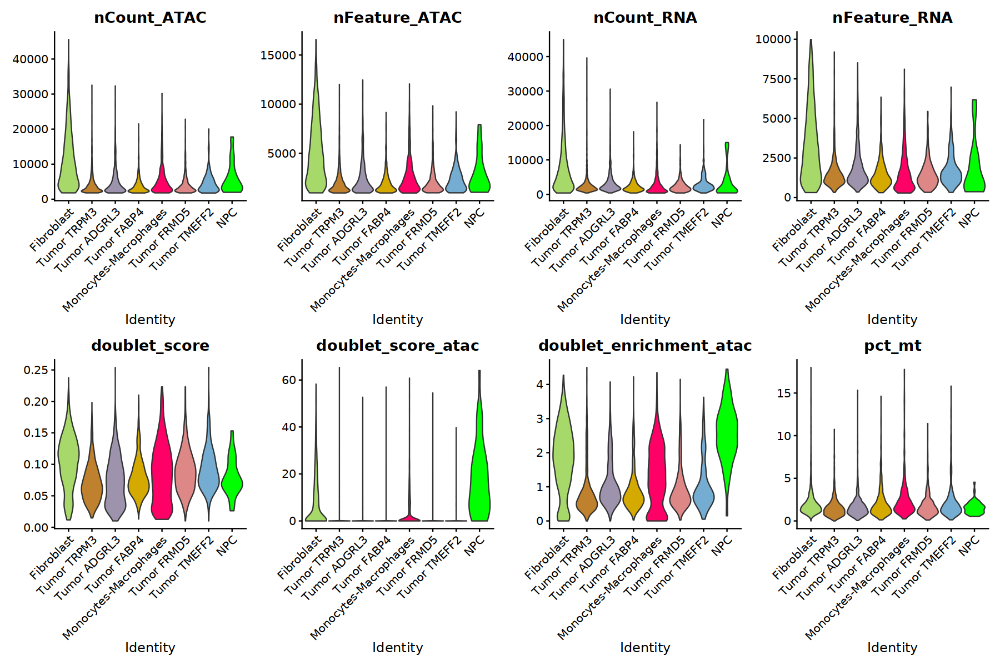

In [76]:
options(repr.plot.width = 15, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars,cols=colors_list, ncol = 4, pt.size = 0)

NPC (nephron progenitor cells) markers

Refs:
- https://doi.org/10.1002/emmm.201201584
- https://doi.org/10.1681/ASN.2017080890
- https://doi.org/10.1186/s13073-019-0615-0

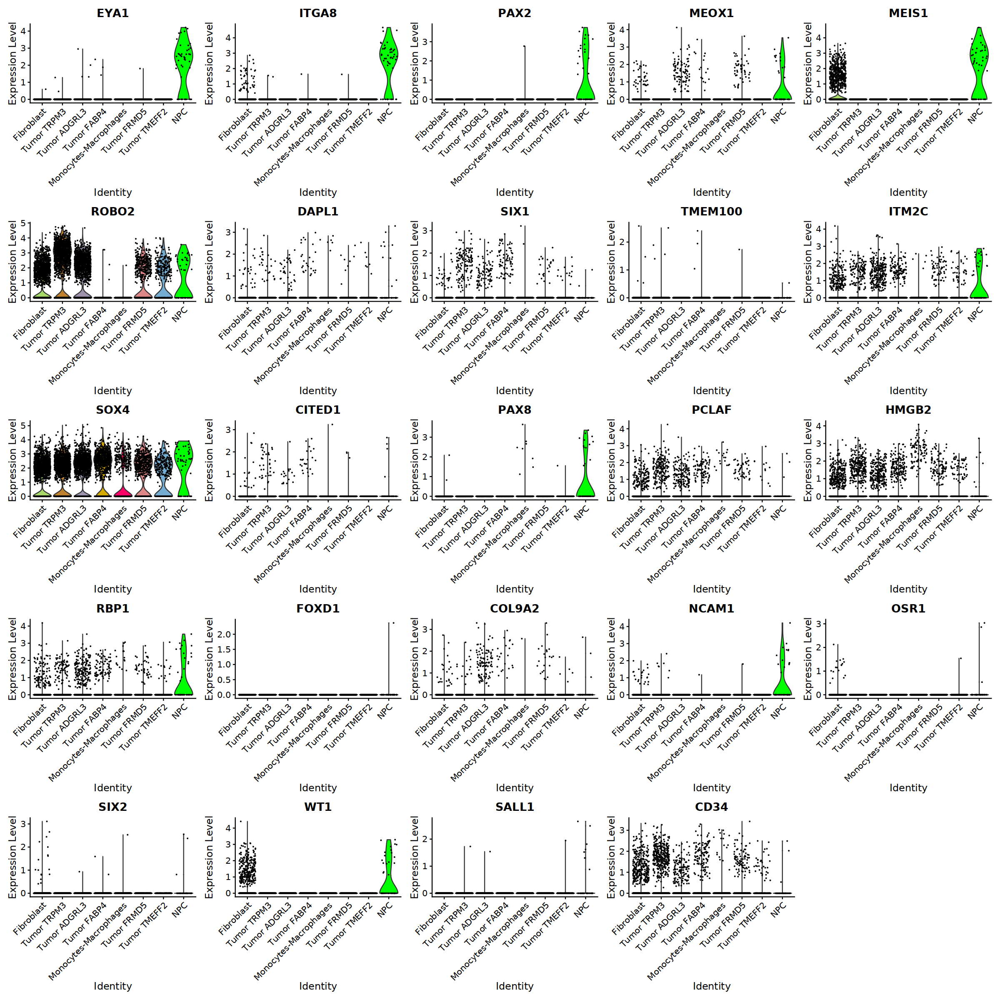

In [77]:
options(repr.plot.width = 20, repr.plot.height = 20)
proge_markers = c("EYA1",  "ITGA8", "PAX2", "MEOX1", "MEIS1", "ROBO2", 
                  "DAPL1", "SIX1", "TMEM100", "ITM2C", "SOX4", "CITED1", 
                  "PAX8", "PCLAF", "HMGB2", "RBP1","FOXD1", 
                  "COL9A2","NCAM1","OSR1", "SIX2","WT1",
                  "SALL1", "CD34")
VlnPlot(seurat_obj, feature=proge_markers,
        cols=colors_list, ncol =5)

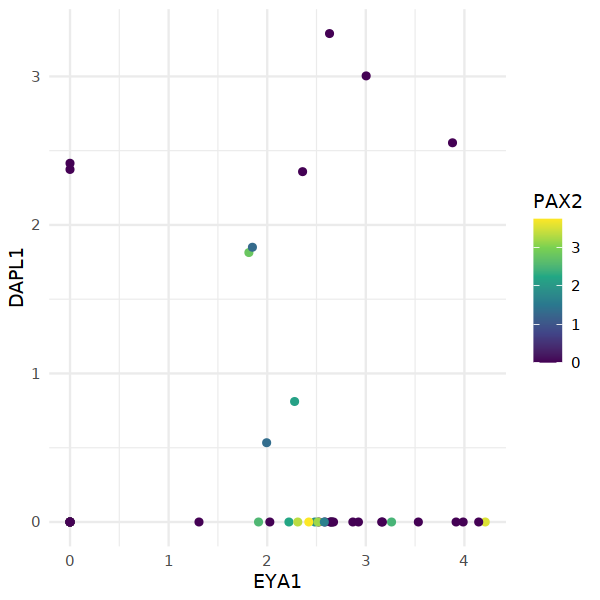

In [78]:
options(repr.plot.width = 5, repr.plot.height = 5)
data <- FetchData(seurat_obj, vars = c(proge_markers, "clusters"))
data <- data[data$clusters == "NPC", ]
ggplot(data, aes(x = EYA1, y = DAPL1, color = PAX2)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

In [79]:
npc_markers <- c(proge_markers,c("HOXD10", "HOXD9", "HOXC8", "HOXA9", "HOXD11", "HOXA3"))

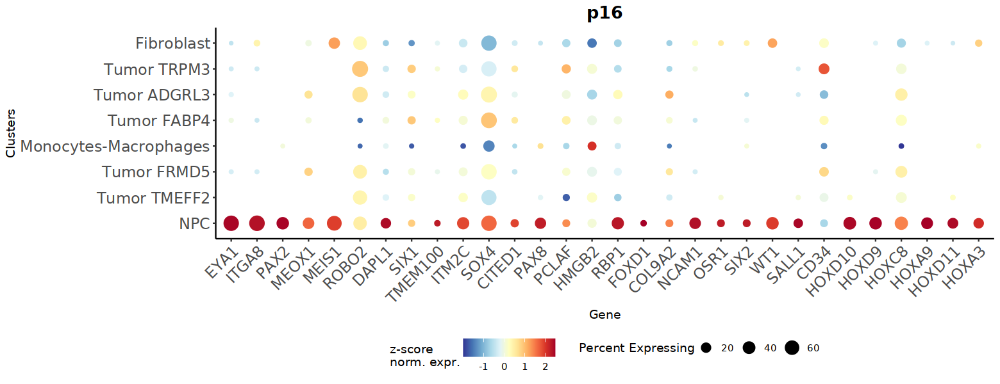

In [80]:
options(repr.plot.width = 13, repr.plot.height = 5, warn=-1,verbose = FALSE)
custom_dp(seurat_obj, 
          unique(npc_markers), 
          TRUE,patient)

Pseudo-bulk per cluster

In [81]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("ROBO1", "PCDH9", "ERBB4"), markers) ## common markers to all clusters

In [82]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

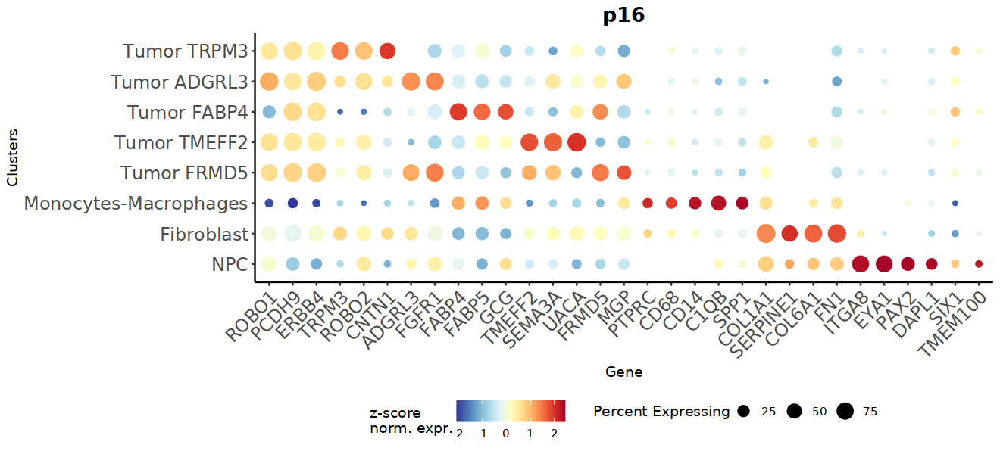

In [83]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, unique(markers), TRUE,patient)
dp1

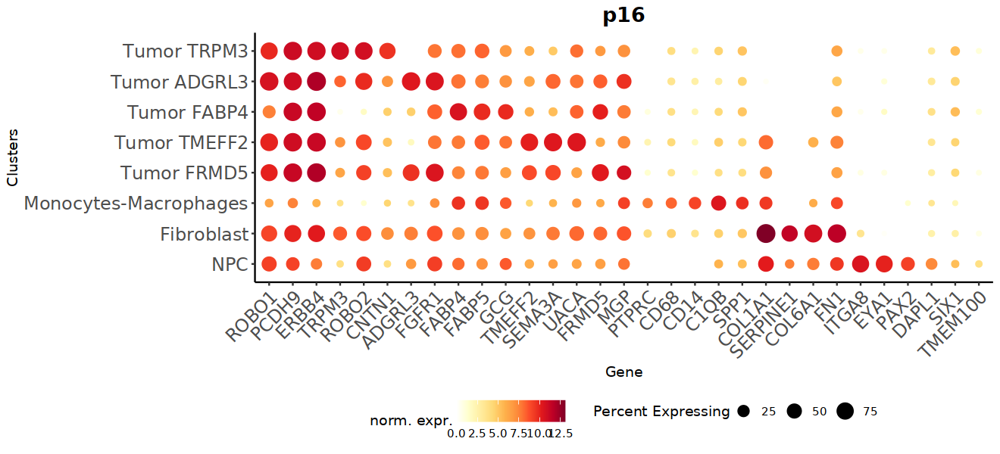

In [84]:
options(repr.plot.width = 11, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, unique(markers), FALSE,patient)
dp2

In [85]:
ggsave(plot = dp1, width = 11, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save 

In [86]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [87]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [88]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [89]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    